In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score,classification_report,confusion_matrix,f1_score)

In [3]:
df = pd.read_csv('dataset_35_dermatology (1).csv')
df.head()
print("Dataset Shape:", df.shape)
print("Columns:")
print(df.columns)
df.info()
df.describe()

Dataset Shape: (366, 35)
Columns:
Index(['erythema', 'scaling', 'definite_borders', 'itching',
       'koebner_phenomenon', 'polygonal_papules', 'follicular_papules',
       'oral_mucosal_involvement', 'knee_and_elbow_involvement',
       'scalp_involvement', 'family_history', 'melanin_incontinence',
       'eosinophils_in_the_infiltrate', 'PNL_infiltrate',
       'fibrosis_of_the_papillary_dermis', 'exocytosis', 'acanthosis',
       'hyperkeratosis', 'parakeratosis', 'clubbing_of_the_rete_ridges',
       'elongation_of_the_rete_ridges',
       'thinning_of_the_suprapapillary_epidermis', 'spongiform_pustule',
       'munro_microabcess', 'focal_hypergranulosis',
       'disappearance_of_the_granular_layer',
       'vacuolisation_and_damage_of_basal_layer', 'spongiosis',
       'saw-tooth_appearance_of_retes', 'follicular_horn_plug',
       'perifollicular_parakeratosis', 'inflammatory_monoluclear_inflitrate',
       'band-like_infiltrate', 'Age', 'class'],
      dtype='object')
<class '

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,class
count,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,...,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000
mean,2.068306,1.795082,1.549180,1.366120,0.633880,0.448087,0.166667,0.377049,0.614754,0.519126,...,0.393443,0.464481,0.456284,0.953552,0.453552,0.103825,0.114754,1.866120,0.554645,2.803279
std,0.664753,0.701527,0.907525,1.138299,0.908016,0.957327,0.570588,0.834147,0.982979,0.905639,...,0.849406,0.864899,0.954873,1.130172,0.954744,0.450433,0.488723,0.726108,1.105908,1.597803
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
50%,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,3.000000
75%,2.000000,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,0.000000,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,2.000000,0.000000,4.000000
max,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,...,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,6.000000


In [5]:
print("Missing Values:")
print(df.isnull().sum())
print("Question mark values:")
print((df == '?').sum())

Missing Values:
erythema                                    0
scaling                                     0
definite_borders                            0
itching                                     0
koebner_phenomenon                          0
polygonal_papules                           0
follicular_papules                          0
oral_mucosal_involvement                    0
knee_and_elbow_involvement                  0
scalp_involvement                           0
family_history                              0
melanin_incontinence                        0
eosinophils_in_the_infiltrate               0
PNL_infiltrate                              0
fibrosis_of_the_papillary_dermis            0
exocytosis                                  0
acanthosis                                  0
hyperkeratosis                              0
parakeratosis                               0
clubbing_of_the_rete_ridges                 0
elongation_of_the_rete_ridges               0
thinning_of_the_su

In [6]:
df.replace('?', np.nan, inplace=True)
df['Age'] = pd.to_numeric(df['Age'])
df['Age'] = df['Age'].fillna(df['Age'].median())
print(df.isnull().sum().sum())

0


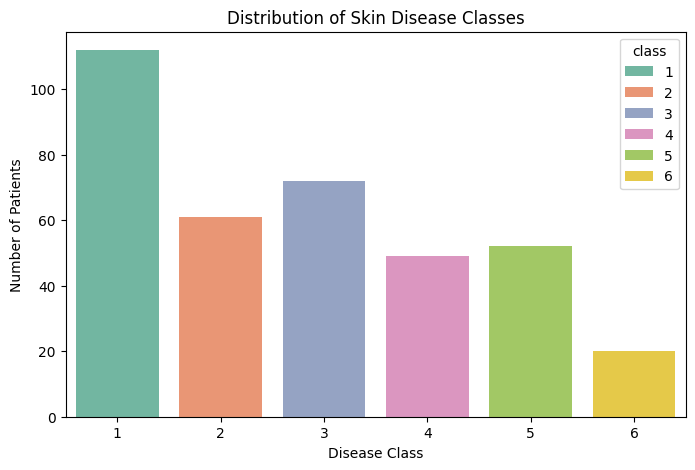

In [8]:
plt.figure(figsize=(8,5))
sns.countplot(x='class', data=df, hue='class', palette='Set2', legend=True)
plt.title("Distribution of Skin Disease Classes")
plt.xlabel("Disease Class")
plt.ylabel("Number of Patients")
plt.show()

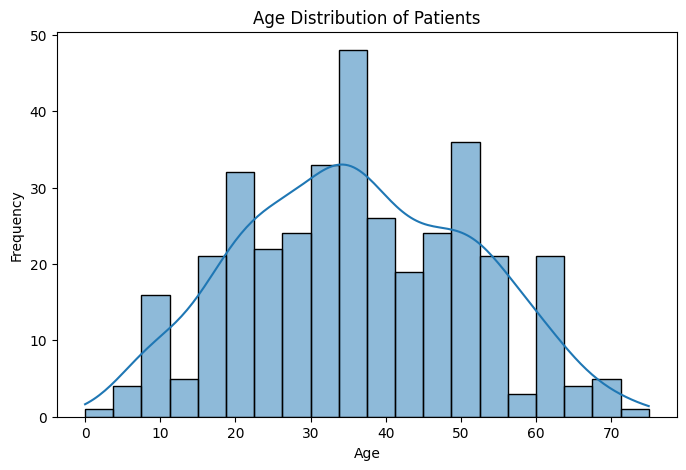

In [9]:
plt.figure(figsize=(8,5))
sns.histplot(df['Age'], bins=20, kde=True)
plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

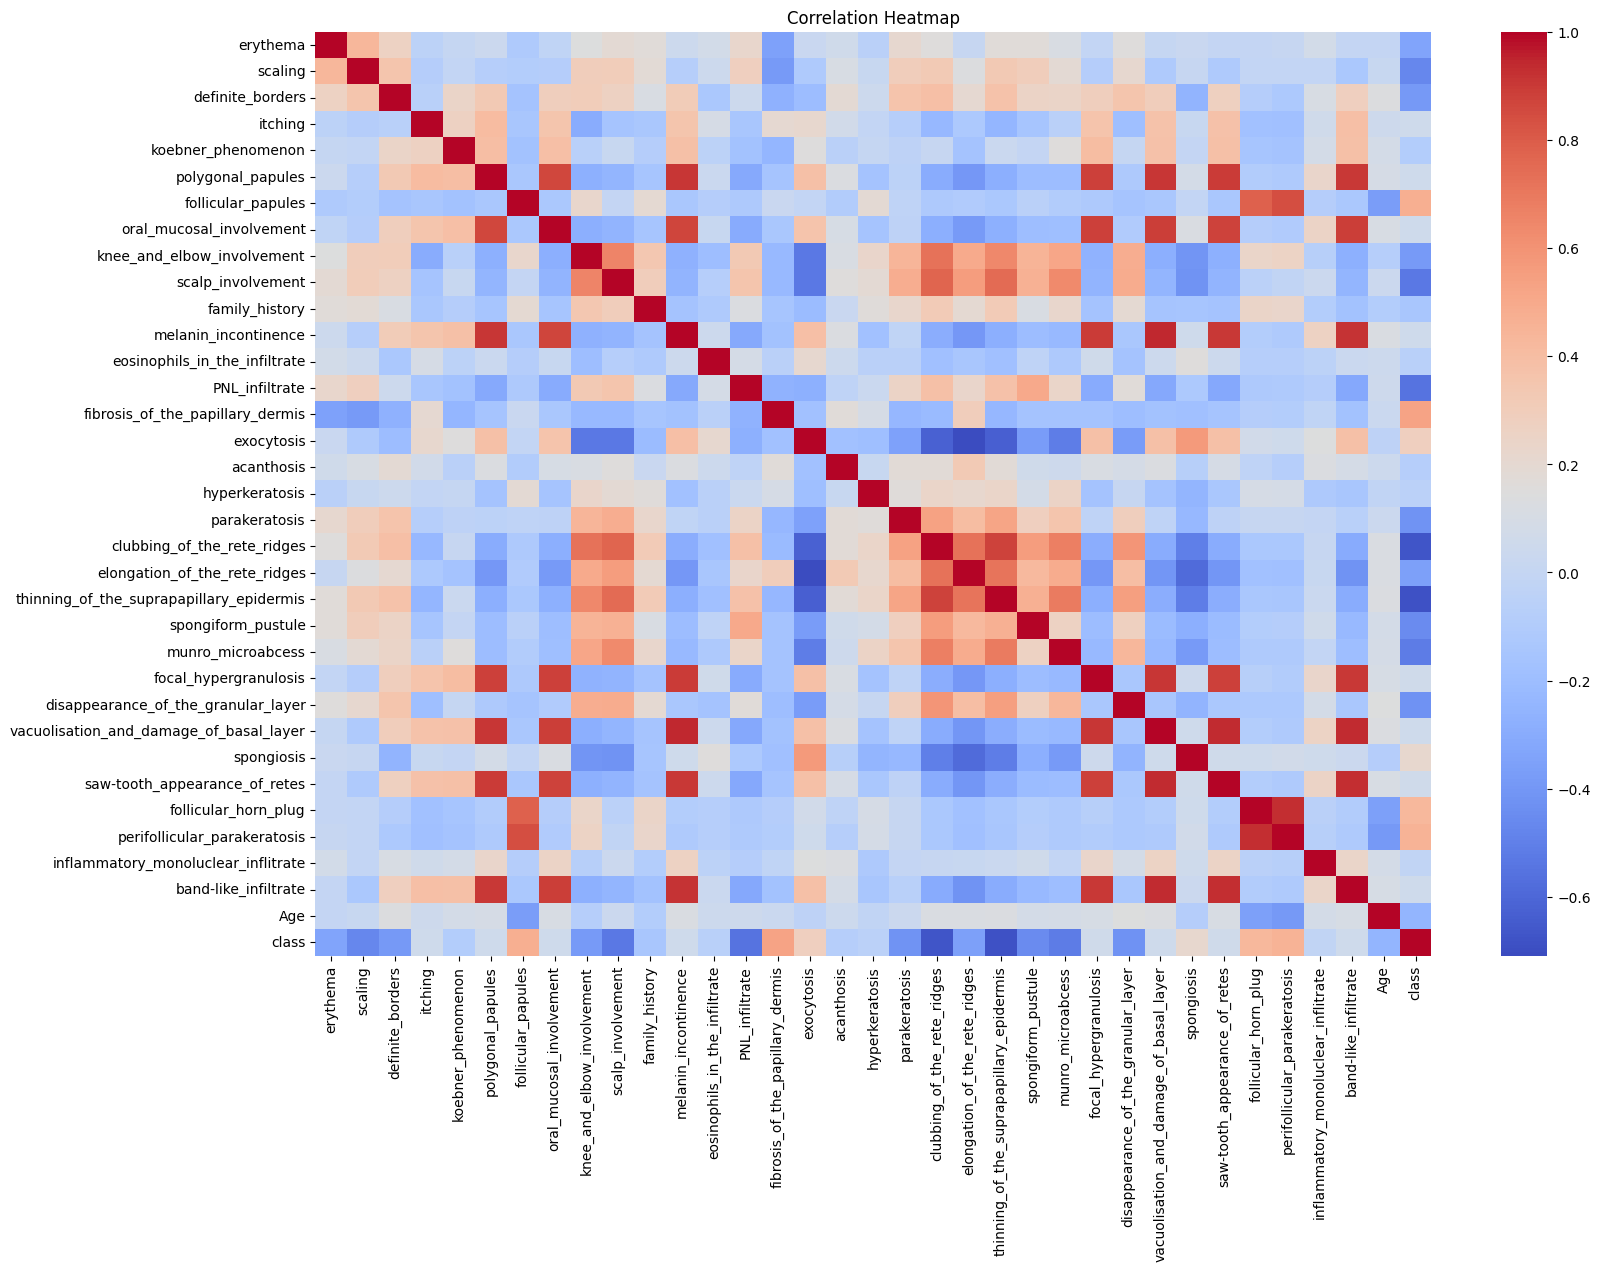

In [10]:
plt.figure(figsize=(18,12))
sns.heatmap(df.corr(),cmap='coolwarm',annot=False)
plt.title("Correlation Heatmap")
plt.show()

In [12]:
X = df.drop('class', axis=1)
y = df['class']
print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

Input Shape: (366, 34)
Target Shape: (366,)


***Class labels of skin disorder are:***


1.   Psoriasis
2.   Seborrheic dermatitis
3.   Lichen planus
4.   Pityriasis rosea
5.   Chronic dermatitis
6.   Pityriasis rubra pilaris



In [13]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (292, 34)
Testing Data: (74, 34)


In [14]:
models = {"Logistic Regression": Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=2000))]),

    "Decision Tree": Pipeline([('imputer', SimpleImputer(strategy='median')),
        ('model', DecisionTreeClassifier(random_state=42))]),

    "Random Forest": Pipeline([('imputer', SimpleImputer(strategy='median')),
        ('model', RandomForestClassifier( n_estimators=100, random_state=42))]),

    "SVM": Pipeline([('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', SVC())])
       }

In [15]:
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')
    results.append({'Model': name,'Accuracy': accuracy,'F1 Score': f1})
    print("Model:", name)
    print("Accuracy:", round(accuracy * 100, 2), "%")
    print("F1 Score:", round(f1, 3))
    print("Classification Report:")
    print(classification_report(y_test, y_pred))

Model: Logistic Regression
Accuracy: 95.95 %
F1 Score: 0.957
Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       1.00      0.83      0.91        12
           3       1.00      0.93      0.97        15
           4       0.77      1.00      0.87        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.96        74
   macro avg       0.96      0.96      0.96        74
weighted avg       0.97      0.96      0.96        74

Model: Decision Tree
Accuracy: 93.24 %
F1 Score: 0.888
Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.83      0.83      0.83        12
           3       1.00      0.93      0.97        15
           4       0.83      1.00      0.91        10
           5       0.91 

In [16]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='F1 Score',ascending=False)
print(results_df)

                 Model  Accuracy  F1 Score
3                  SVM  0.972973  0.969697
0  Logistic Regression  0.959459  0.957362
2        Random Forest  0.959459  0.954451
1        Decision Tree  0.932432  0.887832


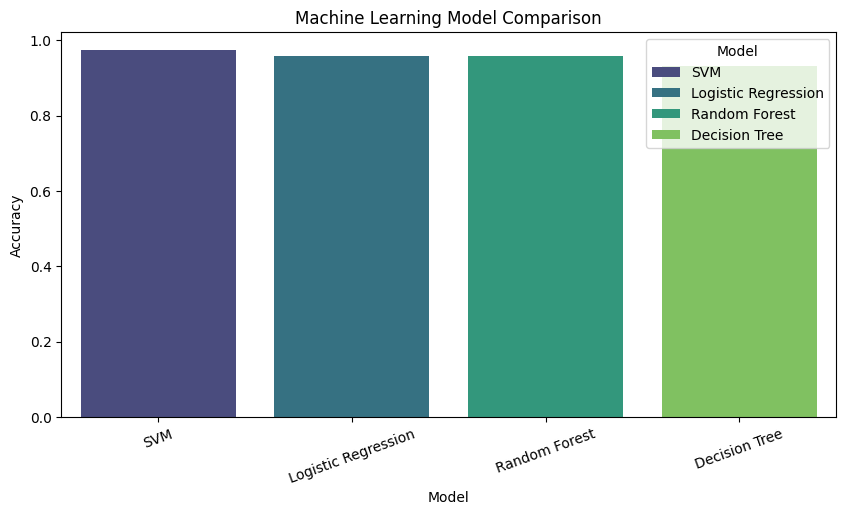

In [17]:
plt.figure(figsize=(10,5))
sns.barplot(data=results_df,x='Model',y='Accuracy',hue='Model',palette='viridis',legend=True)
plt.title("Machine Learning Model Comparison")
plt.ylabel("Accuracy")
plt.xticks(rotation=20)
plt.show()

In [18]:
best_model_name = results_df.iloc[0]['Model']
best_model = models[best_model_name]
print("Best Model:", best_model_name)
print( "Best Accuracy:",round(results_df.iloc[0]['Accuracy'] * 100, 2), "%")
print("Best F1 Score:",round(results_df.iloc[0]['F1 Score'], 3))

Best Model: SVM
Best Accuracy: 97.3 %
Best F1 Score: 0.97


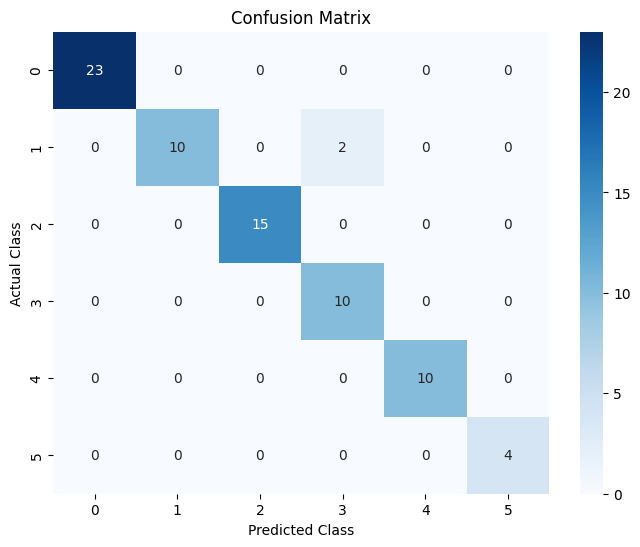

In [19]:
y_pred = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [20]:
rf_model = models['Random Forest']
rf_model.fit(X_train, y_train)
importance = rf_model.named_steps['model'].feature_importances_
feature_importance = pd.DataFrame({'Feature': X.columns,'Importance': importance})
feature_importance = feature_importance.sort_values(by='Importance',ascending=False)
print(feature_importance.head(10))

                                     Feature  Importance
19               clubbing_of_the_rete_ridges    0.099008
14          fibrosis_of_the_papillary_dermis    0.076584
21  thinning_of_the_suprapapillary_epidermis    0.070159
4                         koebner_phenomenon    0.063941
27                                spongiosis    0.059587
20             elongation_of_the_rete_ridges    0.054146
13                            PNL_infiltrate    0.041358
26   vacuolisation_and_damage_of_basal_layer    0.041147
32                      band-like_infiltrate    0.039433
24                     focal_hypergranulosis    0.038467


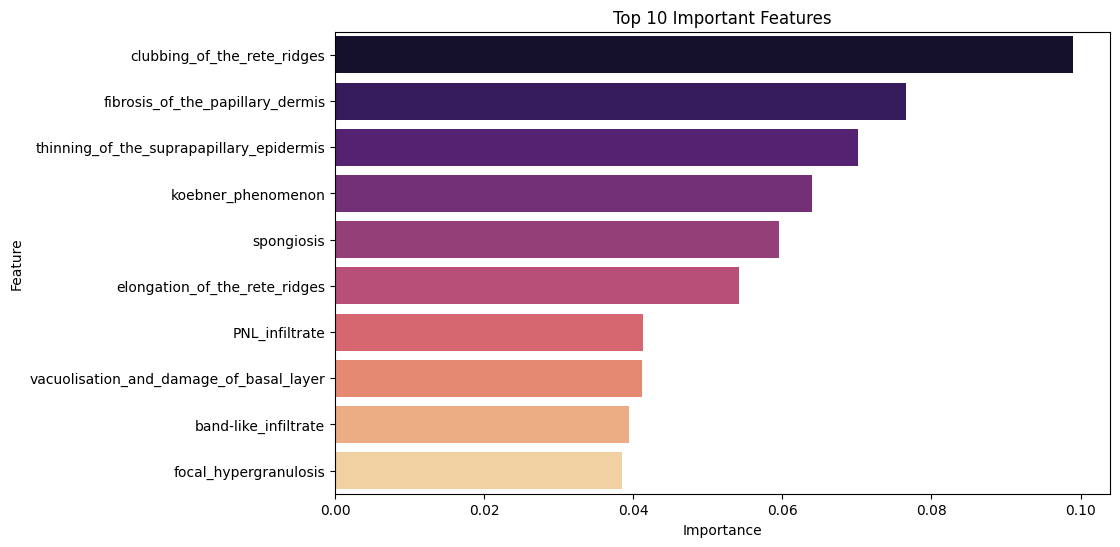

In [21]:
plt.figure(figsize=(10,6))
sns.barplot(data=feature_importance.head(10),x='Importance',y='Feature',hue='Feature',palette='magma',legend=False)
plt.title("Top 10 Important Features")
plt.show()

In [22]:
disease_names = {
    1: "Psoriasis",
    2: "Seborrheic Dermatitis",
    3: "Lichen Planus",
    4: "Pityriasis Rosea",
    5: "Chronic Dermatitis",
    6: "Pityriasis Rubra Pilaris"}

In [23]:
sample_patient = X_test.iloc[[0]]
prediction = best_model.predict(sample_patient)
predicted_disease = disease_names[int(prediction[0])]
print("SKIN DISORDER PREDICTION")
print("Predicted Disease:", predicted_disease)

SKIN DISORDER PREDICTION
Predicted Disease: Seborrheic Dermatitis


# **Challenges**
1.   Missing values in the Age column
2.   The dataset contained categorical target values representing six different skin diseases
3. Different input features had different scales
4. Evaluating the prediction performance across six disease categories



# **Solutions**

1. Replaced missing age values with the median to maintain the dataset
2. Used the class column as the target variable for multiclass classification
3. Applied StandardScaler to standardize features for models such as SVM and Logistic Regression
4. Used a classification report and confusion matrix to evaluate individual class performance



# **Conclusions**
In this project, I developed a Skin Disorder Prediction System using machine learning techniques. I performed data cleaning, exploratory data analysis, feature analysis and model development using four algorithms: Logistic Regression, Decision Tree, Random Forest and Support Vector Machine.Among the four models, Support Vector Machine (SVM) achieved the best performance with 97.30% accuracy and a 96.97% F1-score on the test dataset.

The final model can predict one of six skin disorder categories based on clinical and histopathological attributes. This project demonstrates how machine learning can support the analysis and early identification of skin disorders. However, the system is an educational prototype and requires further clinical validation before any medical application.